<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); padding: 30px; border-radius: 8px; margin-bottom: 25px; box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1);">
    <h1 style="color: #f8fafc; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: 700; margin: 0; font-size: 2.2em; letter-spacing: -0.5px;"> Asignaturas PISA 2012-2022
</h1>
    <p style="color: #94a3b8; font-family: 'Segoe UI', sans-serif; margin: 8px 0 0 0; font-size: 1.1em;"> EDA de las asignaturas de PISA y generación de notas agregadas </p>
    
</div>

Dos partes:

1. **Resultados publicados por la OCDE** (2000-2022, todos los países participantes): qué países participan en cada edición y cómo evolucionan sus notas.
2. **Notas medias por país y por centro** de los 33 países OCDE del proyecto (2012-2022), calculadas desde las tablas maestras. Son las que usan los demás notebooks.

In [1]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.io as pio
import pyarrow.parquet as pq
import seaborn as sns

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.pisa_estadisticas import CLAVES_NIVEL, agregar_pv, reparto_varianza
from src.pisa_pipeline import DOMINIOS, EDICIONES_PISA, columnas_pv, rutas_datos_anuales
from src.pisa_resultados_publicados import plot_comparar_paises, plot_comparar_paises_todas_materias, plot_evolucion_pais
from src.utils_pisa import establecer_semilla

establecer_semilla()
# Renderizador de VS Code: guarda solo los datos de cada figura (el notebook pesa poco) y VS Code las dibuja.
# 'notebook_connected' carga Plotly desde internet y VS Code no lo muestra
pio.renderers.default = 'vscode'

ruta_datos_raw = Path('../../data/raw')
ruta_medias_asignaturas = Path('../../data/intermediate') / 'medias_asignaturas_anual'
EDICIONES = [2012, 2015, 2018, 2022]

✅ Semillas del proyecto establecidas con éxito (seed=42).


# Resultados publicados por la OCDE (2000-2022)

Ficheros `pisa_mathematics_2000_2022.csv`, `pisa_reading_2000_2022.csv` y `pisa_science_2000_2022.csv` de `data/raw`: una fila por país, edición y asignatura, con la media, su error típico, la desviación típica y los percentiles 5 a 95 publicados por la OCDE. Incluyen todos los países participantes, no solo los 33 del proyecto, y la media OCDE (`International Average (OECD)`).

In [2]:
# Carga de archivos y creación de df único.
dfs = []

for subject in ["mathematics", "reading", "science"]:
    df = pd.read_csv(f"../../data/raw/pisa_{subject}_2000_2022.csv")
    df["subject"] = subject
    dfs.append(df)

df_pisa = pd.concat(dfs, ignore_index=True)

In [3]:
df_pisa.columns.tolist()

['year',
 'country',
 'average',
 'standard_error',
 'std_dev',
 'std_dev_se',
 'p5',
 'p5_se',
 'p10',
 'p10_se',
 'p25',
 'p25_se',
 'p50',
 'p50_se',
 'p75',
 'p75_se',
 'p90',
 'p90_se',
 'p95',
 'p95_se',
 'subject']

In [4]:
# Algunos países tienen 2015 separado del resto en un país con nomenclatura: [nombre del país] (2015). Por ejemplo, Argentina no tiene
# valores en 2015, y Argentina (2015) tiene todo nulo excepto 2015. Se combinan.

# Se elimina el (2015) del nombre de la columna
df_pisa["country"] = df_pisa["country"].str.replace(
    r" \(2015\)$", "", regex=True
)

# Ahora que tienen el mismo nombre, se agrupan y se usa .first(), que coge el primer valor no nulo (que será el de la columna
# original excepto en 2015).
df_pisa = (
    df_pisa
    .groupby(["country", "year", "subject"], as_index=False)
    .first()
)

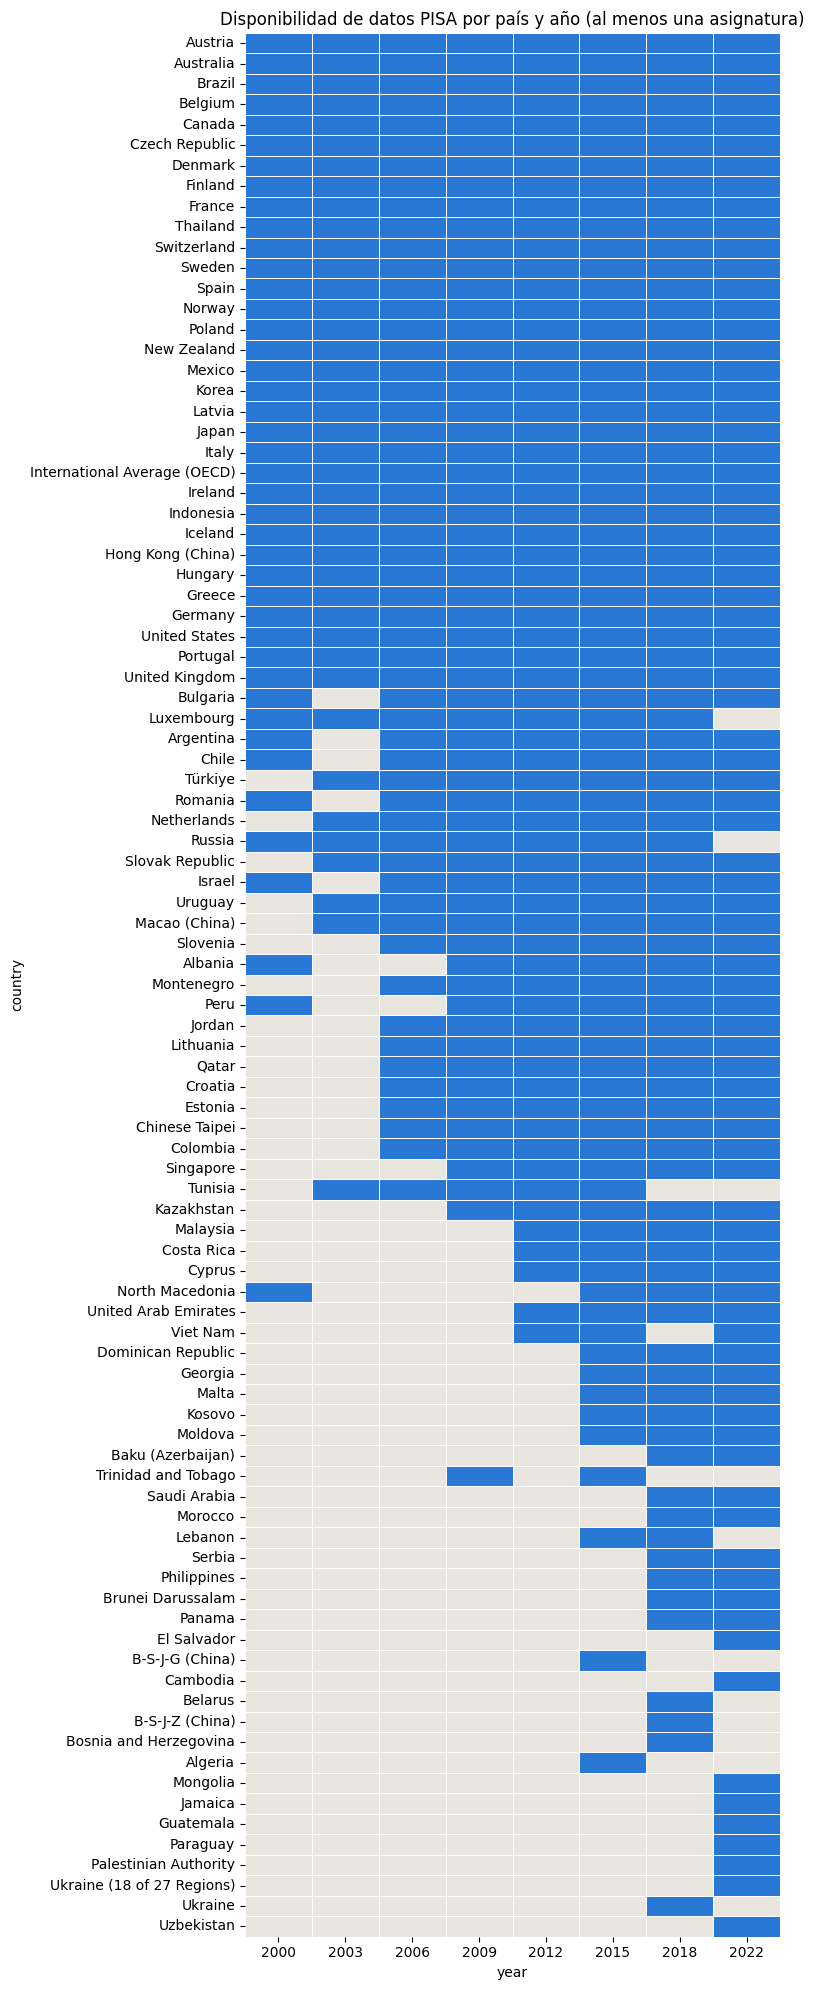

In [5]:
# Participación de países: ver si hay dato en AL MENOS una de las asignaturas por año
participacion = (
df_pisa
.pivot_table(index='country', columns='year', values='average', aggfunc='count')
.fillna(0)
.astype(bool)
)

# Ordenar países por disponibilidad
participacion = participacion.loc[participacion.sum(axis=1).sort_values(ascending=False).index]

# Pintar
fig, ax = plt.subplots(figsize=(8, 20)) # alto porque son ~97 países
sns.heatmap(
participacion,
cmap=['#e8e6df', '#2a78d6'], # gris = no participó, azul = participó
cbar=False,
linewidths=0.5,
linecolor='white',
ax=ax
)
ax.set_title('Disponibilidad de datos PISA por país y año (al menos una asignatura)')
plt.tight_layout()
plt.show()

Varios países, especialmente aquellos que no son miembros de la OCDE, han participado en pocas ediciones y de manera irregular. Se aplica un filtro para excluir países que apenas han participado. Si se quisiese incluir a todos esos países en la visualización, bastaría con comentar las dos celdas siguientes.

In [6]:
# Asegurar que los años están ordenados
participacion = participacion.sort_index(axis=1)

# Últimas 4 ediciones
ultimas_4 = participacion.columns[-4:]

# Condición 1: participó en las 4 últimas ediciones
cond_ultimas_4 = participacion[ultimas_4].all(axis=1)

# Condición 2: participó en al menos 6 ediciones
cond_6_total = participacion.sum(axis=1) >= 6

# Países que cumplen alguna de las dos
paises_validos = participacion.index[
    cond_ultimas_4 | cond_6_total
]

# Filtrar el dataframe original
df_pisa_filtrado = df_pisa[df_pisa["country"].isin(paises_validos)]

In [7]:
paises_descartados = participacion.index.difference(paises_validos)

print(f"Se conservan {len(paises_validos)} países.")
print(f"Se eliminan {len(paises_descartados)} países.")
print(sorted(paises_descartados))

Se conservan 61 países.
Se eliminan 32 países.
['Algeria', 'B-S-J-G (China)', 'B-S-J-Z (China)', 'Baku (Azerbaijan)', 'Belarus', 'Bosnia and Herzegovina', 'Brunei Darussalam', 'Cambodia', 'Dominican Republic', 'El Salvador', 'Georgia', 'Guatemala', 'Jamaica', 'Kosovo', 'Lebanon', 'Malta', 'Moldova', 'Mongolia', 'Morocco', 'North Macedonia', 'Palestinian Authority', 'Panama', 'Paraguay', 'Philippines', 'Saudi Arabia', 'Serbia', 'Trinidad and Tobago', 'Tunisia', 'Ukraine', 'Ukraine (18 of 27 Regions)', 'Uzbekistan', 'Viet Nam']


## Evolución de las notas

Gráficos interactivos (funciones de `src/pisa_resultados_publicados.py`): España en las tres asignaturas y su media; España frente a la media OCDE en el percentil 90 de matemáticas (el 10 % de alumnos con mejor nota); España frente a Portugal, Francia, Italia y Alemania; y cuatro países OCDE elegidos al azar (con la semilla fijada) junto a la media OCDE.

In [8]:
paises_ocde = [
    "Australia",
    "Austria",
    "Belgium",
    "Canada",
    "Chile",
    "Colombia",
    "Costa Rica",
    "Czech Republic",
    "Denmark",
    "Estonia",
    "Finland",
    "France",
    "Germany",
    "Greece",
    "Hungary",
    "Iceland",
    "Ireland",
    "Israel",
    "Italy",
    "Japan",
    "Korea",
    "Latvia",
    "Lithuania",
    "Luxembourg",
    "Mexico",
    "Netherlands",
    "New Zealand",
    "Norway",
    "Poland",
    "Portugal",
    "Slovak Republic",
    "Slovenia",
    "Spain",
    "Sweden",
    "Switzerland",
    "Türkiye",
    "United Kingdom",
    "United States"
]

media_ocde = "International Average (OECD)"

lista_paises_completa = df_pisa_filtrado.country.unique().tolist()
lista_paises_completa.remove(media_ocde)

In [9]:
df_pisa_eda = df_pisa_filtrado.copy()

In [10]:
evo_fig_1 = plot_evolucion_pais(df_pisa_eda, "Spain")
evo_fig_1.show()

In [11]:
comp_fig_1 = plot_comparar_paises(df=df_pisa_eda, paises=["Spain", media_ocde], materia="mathematics", metrica="p90") # La métrica es 'p90' en lugar de la media. p90 = top 10% de alumnos
comp_fig_1.show()

In [12]:
comp_all_fig_1 = plot_comparar_paises_todas_materias(df=df_pisa_eda, paises=["Spain", "Portugal", "France", "Italy", "Germany"])
comp_all_fig_1.show()

In [13]:
lista_paises = random.sample(paises_ocde, 4) # Utilizar lista_paises_completa para incluir todos los países.
lista_paises.append(media_ocde) # OPCIONAL: nos aseguramos de que la media de la OCDE siempre esté presente.

random_sample_fig = plot_comparar_paises_todas_materias(df_pisa_eda, lista_paises)
random_sample_fig.show()

# Notas medias por país y por centro (2012-2022)

Nota media de cada asignatura (`MATH`, `READ`, `SCIE`) desde las tablas maestras de `00_pipeline_multiedicion_PISA`: se promedian los valores plausibles de cada alumno y se pondera por `W_FSTUWT` (`agregar_pv` de `src/pisa_estadisticas.py`). El centro se identifica con `CNT` + `CNTSCHID`, porque en 2012 `CNTSCHID` se repite entre países.

Se guardan en `data/intermediate/medias_asignaturas_anual/` (`pisa_medias_asignaturas_pais_anual.parquet` y `pisa_medias_asignaturas_centro_anual.parquet`). Es la nota media que usan los demás notebooks: por centro, el panel de `02_data_panel_modelos`; por país, `01_EDA_factores_macroeconomicos` y la media OCDE de cada edición en `03_modelado`.

In [14]:
# Nota media de cada asignatura por país y por centro, en cada edición
medias_por_nivel = {'pais': [], 'centro': []}
for edicion in EDICIONES:
    ruta_estudiantes, _ = rutas_datos_anuales(str(ruta_datos_raw), edicion)
    columnas_pv_edicion = [columna for columna in pq.ParquetFile(ruta_estudiantes).schema.names
                           if any(columna in columnas_pv(dominio) for dominio in DOMINIOS)]
    alumnos = pd.read_parquet(ruta_estudiantes, columns=['CNT', 'CNTSCHID', 'W_FSTUWT'] + columnas_pv_edicion)
    for nivel, tablas in medias_por_nivel.items():
        medias_edicion = None
        for dominio in DOMINIOS:
            media = agregar_pv(alumnos, dominio, nivel, nombre=f'media_{dominio.lower()}_{nivel}')
            medias_edicion = media if medias_edicion is None else medias_edicion.merge(media, on=CLAVES_NIVEL[nivel], validate='one_to_one')
        tablas.append(medias_edicion.assign(year=edicion))

df_medias_pais = pd.concat(medias_por_nivel['pais'], ignore_index=True).sort_values(['year', 'CNT'], ascending=False, ignore_index=True)
df_medias_centro = pd.concat(medias_por_nivel['centro'], ignore_index=True).sort_values(['year', 'CNT', 'CNTSCHID'], ascending=False, ignore_index=True)

df_medias_pais.to_parquet(ruta_medias_asignaturas / 'pisa_medias_asignaturas_pais_anual.parquet', index=False)
df_medias_centro.to_parquet(ruta_medias_asignaturas / 'pisa_medias_asignaturas_centro_anual.parquet', index=False)
print(f'medias por país: {df_medias_pais.shape} | por centro: {df_medias_centro.shape} -> {ruta_medias_asignaturas}')
print('centros por edición:', df_medias_centro.groupby('year').size().to_dict())
df_medias_centro.head()

medias por país: (132, 5) | por centro: (41298, 6) -> ..\..\data\intermediate\medias_asignaturas_anual
centros por edición: {2012: 11725, 2015: 9076, 2018: 10366, 2022: 10131}


,CNT,CNTSCHID,media_math_centro,media_read_centro,media_scie_centro,year
0,USA,84000163,388.667326,406.987893,413.315619,2022
1,USA,84000162,527.321790,540.685498,575.180552,2022
2,USA,84000161,385.266026,420.096352,407.733427,2022
3,USA,84000160,492.090707,528.801348,524.854801,2022
4,USA,84000159,492.248879,545.676243,531.463219,2022


# Estructura multinivel de la nota

Reparto de la varianza de la nota entre países, entre centros de un mismo país y entre alumnos de un mismo centro, en cada edición y asignatura (sumas de cuadrados anidadas, `reparto_varianza` de `src/pisa_estadisticas.py`):

* **Ponderado con `SENWT`**: cada país pesa igual (5.000), así que el reparto no depende del tamaño de su muestra.
* **Con cada valor plausible por separado**: se reparte la varianza de cada uno y se promedian los porcentajes (10 valores plausibles; 5 en 2012). Promediar antes los valores plausibles de cada alumno reduciría la variación entre alumnos.
* **Las tres asignaturas en todas las ediciones**, para que las cifras se puedan comparar entre ediciones. La tabla marca el dominio principal de cada edición (el que tiene más preguntas).

Es un reparto descriptivo, no un modelo multinivel: en los centros con pocos alumnos evaluados, la media del centro tiene ruido de muestreo, que infla algo la parte entre centros.

In [15]:
# Reparto de la varianza de cada valor plausible (ponderado con SENWT); los porcentajes son la media de los de cada uno
niveles_alumnos = {'entre países': CLAVES_NIVEL['pais'], 'entre centros (dentro del país)': CLAVES_NIVEL['centro']}
filas_varianza = []
for edicion in EDICIONES:
    ruta_estudiantes, _ = rutas_datos_anuales(str(ruta_datos_raw), edicion)
    columnas_parquet = pq.ParquetFile(ruta_estudiantes).schema.names
    pv_por_dominio = {dominio: [columna for columna in columnas_pv(dominio) if columna in columnas_parquet] for dominio in DOMINIOS}
    alumnos = pd.read_parquet(ruta_estudiantes, columns=['CNT', 'CNTSCHID', 'SENWT'] + [columna for columnas in pv_por_dominio.values() for columna in columnas])
    for dominio, columnas_dominio in pv_por_dominio.items():
        reparto_medio = pd.DataFrame([reparto_varianza(alumnos, columna, niveles_alumnos, 'entre alumnos (dentro del centro)', peso_col='SENWT')
                                      for columna in columnas_dominio]).mean()
        filas_varianza.append({'edición': edicion, 'asignatura': dominio, 'dominio principal': 'sí' if dominio == EDICIONES_PISA[edicion]['dominio_principal'] else '',
                               **reparto_medio.to_dict(), 'valores plausibles': len(columnas_dominio)})
varianza_por_edicion = pd.DataFrame(filas_varianza).set_index(['edición', 'asignatura'])
varianza_por_edicion.round(1)

dominio principal  entre países  \
edición asignatura                                   
2012    MATH                      sí           9.3   
        READ                                   6.0   
        SCIE                                   8.7   
2015    MATH                                   9.2   
        READ                                   6.2   
        SCIE                      sí           8.1   
2018    MATH                                   8.1   
        READ                      sí           4.8   
        SCIE                                   6.2   
2022    MATH                      sí           8.1   
        READ                                   5.2   
        SCIE                                   6.6   

                    entre centros (dentro del país)  \
edición asignatura                                    
2012    MATH                                   36.1   
        READ                                   38.0   
        SCIE                                   34.6   
2015    MATH                                   31.4   
        READ                                   33.0   
        SCIE                                   31.2   
2018    MATH                                   32.2   
        READ                                   32.0   
        SCIE                                   31.4   
2022    MATH                                   32.5   
        READ                                   30.6   
        SCIE                                   30.5   

                    entre alumnos (dentro del centro)  valores plausibles  
edición asignatura                                                         
2012    MATH                                     54.6                   5  
        READ                                     56.0                   5  
        SCIE                                     56.7                   5  
2015    MATH                                     59.4                  10  
        READ                                     60.9                  10  
        SCIE                                     60.7                  10  
2018    MATH                                     59.7                  10  
        READ                                     63.2                  10  
        SCIE                                     62.4                  10  
2022    MATH                                     59.3                  10  
        READ                                     64.2                  10  
        SCIE                                     62.8                  10

* **La mayor parte de la varianza de la nota está dentro de cada país.** Entre países queda del 4,8 % (lectura, 2018) al 9,3 % (matemáticas, 2012); entre centros de un mismo país, del 30,5 % al 38,0 %; y entre alumnos de un mismo centro, del 54,6 % al 64,2 %.
* **Matemáticas es la asignatura que más separa a los países** en todas las ediciones (del 8,1 % al 9,3 % de la varianza), lectura la que menos (del 4,8 % al 6,2 %) y ciencias queda en medio (del 6,2 % al 8,7 %).
* **El reparto cambia poco entre ediciones**: en matemáticas, la parte entre países pasa del 9,3 % en 2012 al 8,1 % en 2022. En 2012 la parte entre alumnos es algo menor (del 54,6 % al 56,7 %) que en las demás ediciones (del 59,3 % al 64,2 %).